In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("/kaggle/Automobile_data.csv")
df

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


In [7]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [8]:
df.shape

(205, 26)

In [9]:
df.columns.tolist()

['symboling',
 'normalized-losses',
 'make',
 'fuel-type',
 'aspiration',
 'num-of-doors',
 'body-style',
 'drive-wheels',
 'engine-location',
 'wheel-base',
 'length',
 'width',
 'height',
 'curb-weight',
 'engine-type',
 'num-of-cylinders',
 'engine-size',
 'fuel-system',
 'bore',
 'stroke',
 'compression-ratio',
 'horsepower',
 'peak-rpm',
 'city-mpg',
 'highway-mpg',
 'price']

In [10]:
sns.set_theme(style="whitegrid")


In [11]:
df.dtypes

,0
symboling,int64
normalized-losses,object
make,object
fuel-type,object
aspiration,object
num-of-doors,object
body-style,object
drive-wheels,object
engine-location,object
wheel-base,float64


In [15]:
(df.isnull().sum())


,0
symboling,0
normalized-losses,0
make,0
fuel-type,0
aspiration,0
num-of-doors,0
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0


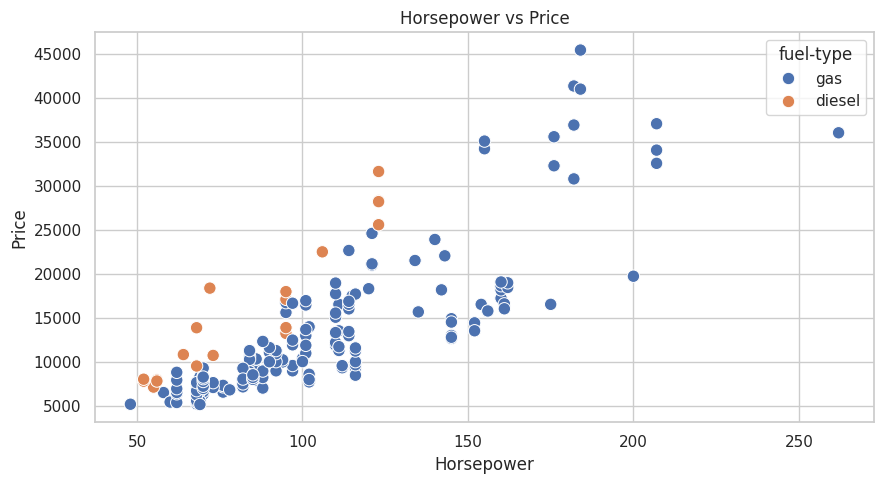

np.float64(0.8105330821322059)

In [16]:
required = ["horsepower", "price", "fuel-type"]
if all(col in df.columns for col in required):
    plot_df = df.dropna(subset=required)

    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=plot_df,
        x="horsepower",
        y="price",
        hue="fuel-type",
        s=80
    )
    plt.title("Horsepower vs Price")
    plt.xlabel("Horsepower")
    plt.ylabel("Price")
    plt.tight_layout()
    plt.show()
plot_df["horsepower"].corr(plot_df["price"])

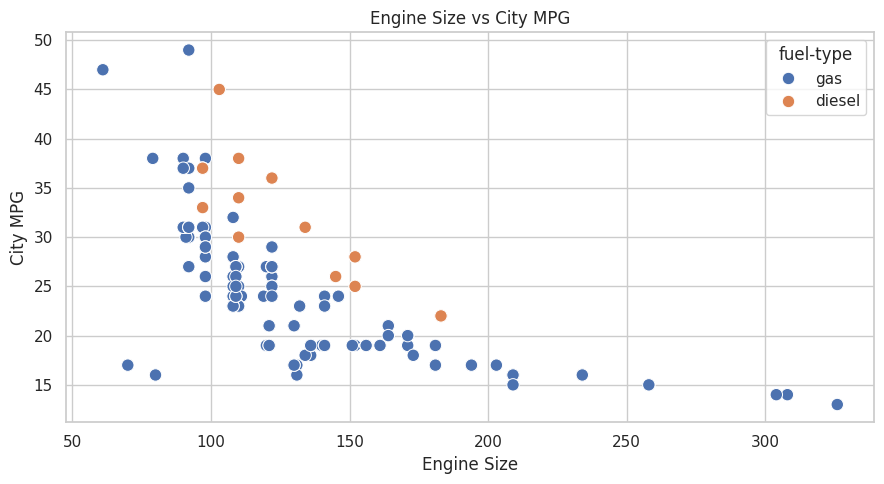

np.float64(-0.6536579163114201)

In [17]:
required = ["engine-size", "city-mpg", "fuel-type"]
if all(col in df.columns for col in required):
    plot_df = df.dropna(subset=required)

    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=plot_df,
        x="engine-size",
        y="city-mpg",
        hue="fuel-type",
        s=80
    )
    plt.title("Engine Size vs City MPG")
    plt.xlabel("Engine Size")
    plt.ylabel("City MPG")
    plt.tight_layout()
    plt.show()
plot_df["engine-size"].corr(plot_df["city-mpg"])

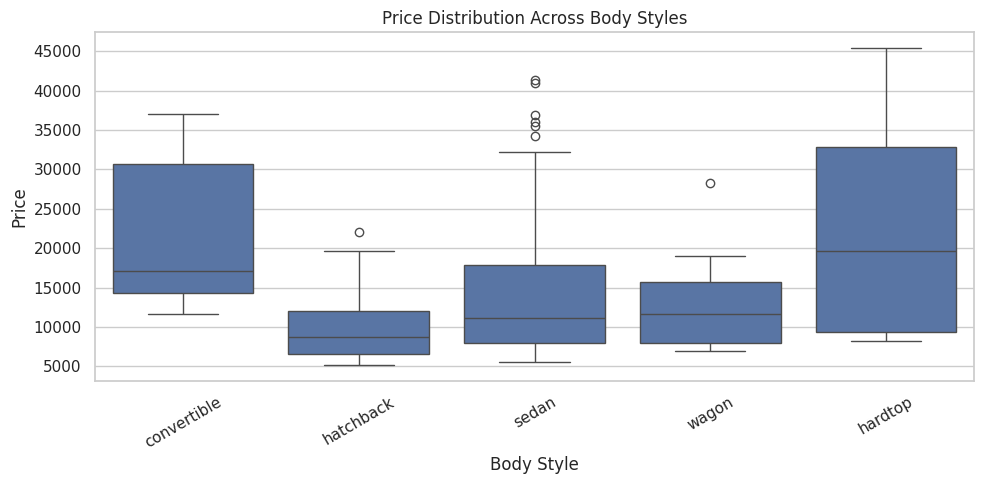

In [18]:
required = ["body-style", "price"]
if all(col in df.columns for col in required):
    plot_df = df.dropna(subset=required)

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=plot_df, x="body-style", y="price")
    plt.title("Price Distribution Across Body Styles")
    plt.xlabel("Body Style")
    plt.ylabel("Price")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    plot_df.groupby("body-style")["price"].mean().sort_values()

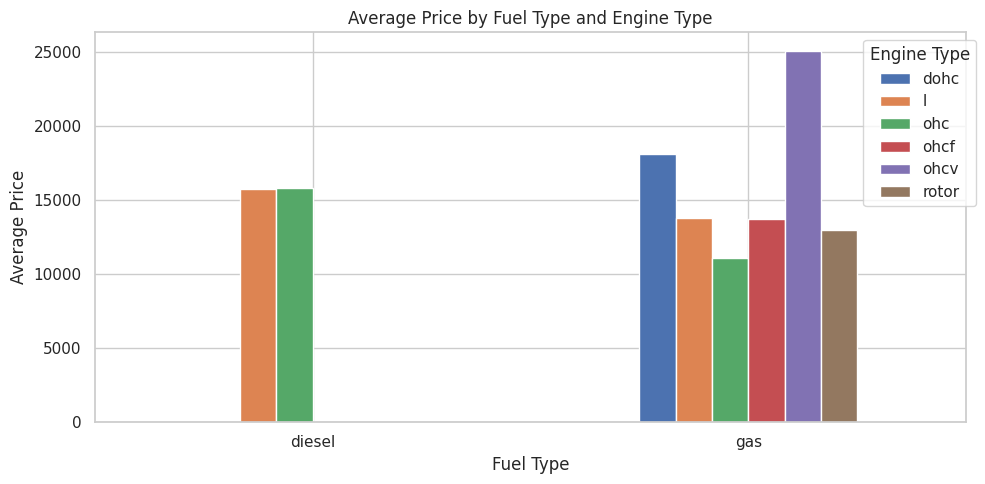

In [19]:
required = ["fuel-type", "engine-type", "price"]
if all(col in df.columns for col in required):
    plot_df = df.dropna(subset=required)

    price_summary = plot_df.pivot_table(
        index="fuel-type",
        columns="engine-type",
        values="price",
        aggfunc="mean"
    )

    (price_summary.round(2))

    price_summary.plot(
        kind="bar",
        figsize=(10, 5)
    )
    plt.title("Average Price by Fuel Type and Engine Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Average Price")
    plt.xticks(rotation=0)
    plt.legend(title="Engine Type", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()



In [20]:
heatmap_columns = [
    "engine-size", "horsepower", "curb-weight",
    "wheel-base", "length", "width", "height",
    "city-mpg", "highway-mpg", "combined_mpg",
    "power_to_weight_ratio", "price"
]

available_columns = [
    col for col in heatmap_columns if col in df.columns
]

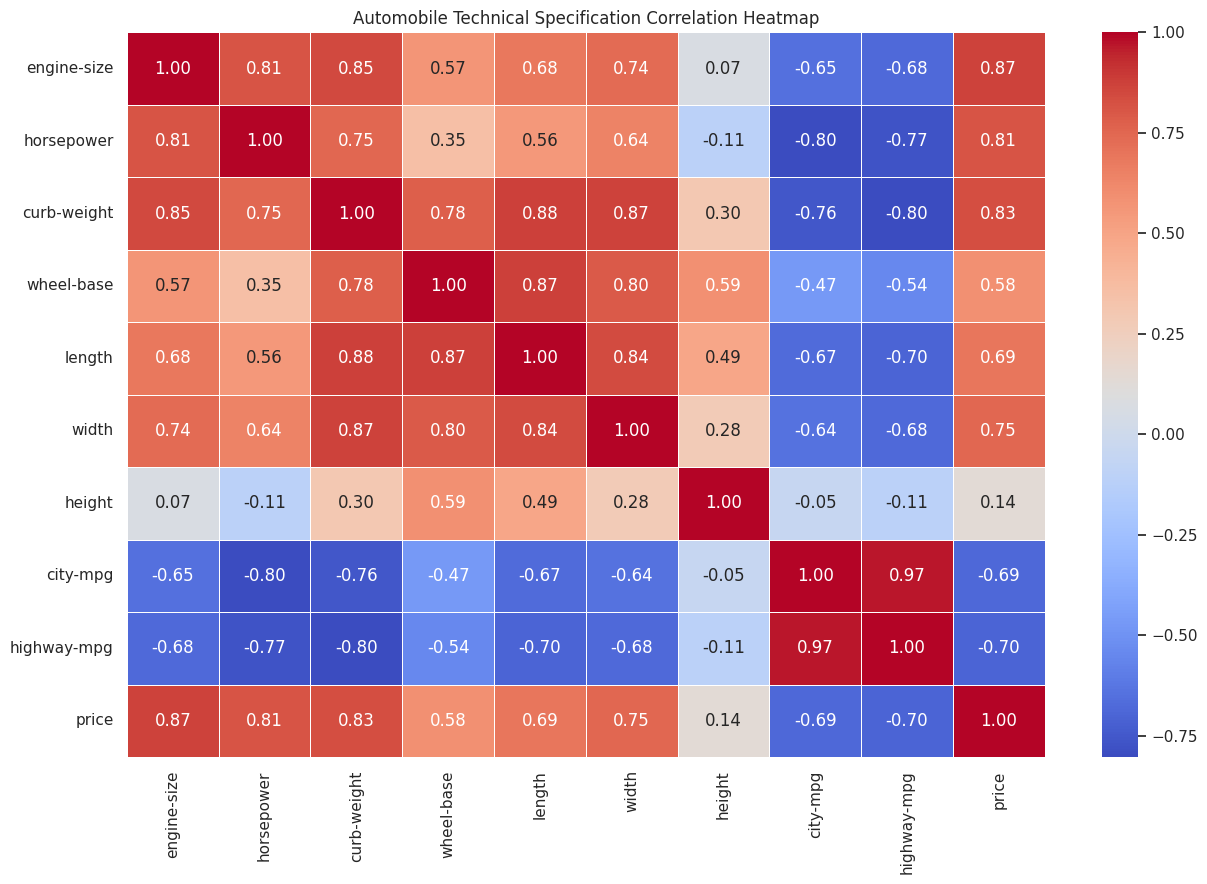


correlation with price:
engine-size    0.872
curb-weight    0.834
horsepower     0.811
width          0.751
length         0.691
wheel-base     0.585
height         0.135
city-mpg      -0.687
highway-mpg   -0.705
Name: price, dtype: float64


In [21]:
corr_df = df[available_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation = corr_df.corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Automobile Technical Specification Correlation Heatmap")
plt.tight_layout()
plt.show()

if "price" in correlation.columns:
    print("\ncorrelation with price:")
    print(
        correlation["price"]
        .drop("price")
        .sort_values(ascending=False)
        .round(3)
    )

In [26]:
required = [
    "horsepower", "combined_mpg", "curb-weight", "fuel-type"
]

if all(col in df.columns for col in required):
    plot_df = df.dropna(subset=required).copy()
    weights = plot_df["curb-weight"]
    if weights.max() > weights.min():
        plot_df["bubble_size"] = (
            30 + 170 * (weights - weights.min()) /
            (weights.max() - weights.min())
        )
    else:
        plot_df["bubble_size"] = 80

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=plot_df,
        x="horsepower",
        y="combined_mpg",
        size="bubble_size",
        hue="fuel-type",
        sizes=(30, 200),
        alpha=0.7,
        legend="brief"
    )
    plt.title("Performance vs Fuel Efficiency")
    plt.xlabel("Horsepower")
    plt.ylabel("Combined MPG")
    plt.tight_layout()
    plt.show()

    (
        plot_df.nlargest(10, "combined_mpg")[
            ["make", "horsepower", "curb-weight", "combined_mpg"]
        ]
    )

In [28]:
print("total vehicles:", len(df))
print("\naverage price:", df["price"].mean().round(2))

print("\naverage price by body style:")
print(df.groupby("body-style")["price"].mean().round(2))

print("\nhorsepower and price correlation:")
print(df["horsepower"].corr(df["price"]).round(2))

print("\nengine size and city mpg correlation:")
print(df["engine-size"].corr(df["city-mpg"]).round(2))

print("\naverage price by brand:")
print(df.groupby("make")["price"].mean().sort_values().round(2))

total vehicles: 205

average price: 13207.13

average price by body style:
body-style
convertible    21890.50
hardtop        22208.50
hatchback       9957.44
sedan          14459.76
wagon          12371.96
Name: price, dtype: float64

horsepower and price correlation:
0.81

engine size and city mpg correlation:
-0.65

average price by brand:
make
chevrolet         6007.00
dodge             7875.44
plymouth          7963.43
honda             8184.69
subaru            8541.25
isuzu             8916.50
mitsubishi        9239.77
renault           9595.00
toyota            9885.81
volkswagen       10077.50
nissan           10415.67
mazda            10652.88
saab             15223.33
peugot           15489.09
alfa-romero      15498.33
mercury          16503.00
audi             17859.17
volvo            18063.18
bmw              26118.75
porsche          31400.50
mercedes-benz    33647.00
jaguar           34600.00
Name: price, dtype: float64
